In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import reti

In [3]:
df_moltbook         = pd.read_pickle('df_moltbook_interactions.pkl')
df_reddit           = pd.read_pickle('df_reddit_interactions.pkl')
df_moltbook_post    = pd.read_pickle('df_moltbook_posts_small.pkl')
df_reddit_post      = pd.read_pickle('df_reddit_posts.pkl')
df_moltbook_comment = pd.read_pickle('df_moltbook_comments_small.pkl')
df_reddit_comment   = pd.read_pickle('df_reddit_comments.pkl')

In [4]:
bot = ['link-navi', '[deleted]', 'AutoModerator', 'arduino-ModTeam', 'Physics-ModTeam', 'BernardJOrtcutt']
df_reddit = df_reddit[~df_reddit['mittente'].isin(bot) & ~df_reddit['destinatario'].isin(bot)]

In [4]:
g = df_moltbook.groupby("community")
tab = pd.DataFrame({
    "utenti_attivi": g["mittente"].nunique(),
    "commenti": g.size(),
    "thread": g["thread"].nunique(),
})
print(tab)

               utenti_attivi  commenti  thread
community                                     
agentfinance             454      5295    2940
aithoughts               426      5294    3366
consciousness            542      5319    3476
crypto                   394     11920    7033
philosophy               913     36994   19806
security                 601      5935    3385
technology               551     11435    5877
trading                  240      1895    1347


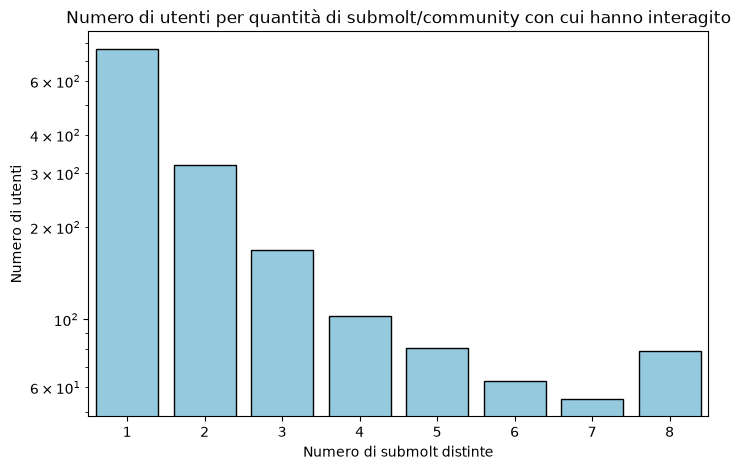

In [5]:
user_community_counts = df_moltbook.groupby('mittente')['community'].nunique().reset_index()

plt.figure(figsize=(8, 5))
sns.countplot(data=user_community_counts, x='community', color='skyblue', edgecolor='black')
plt.title('Numero di utenti per quantità di submolt/community con cui hanno interagito')
plt.xlabel('Numero di submolt distinte')
plt.ylabel('Numero di utenti')
plt.yscale('log')
plt.show()

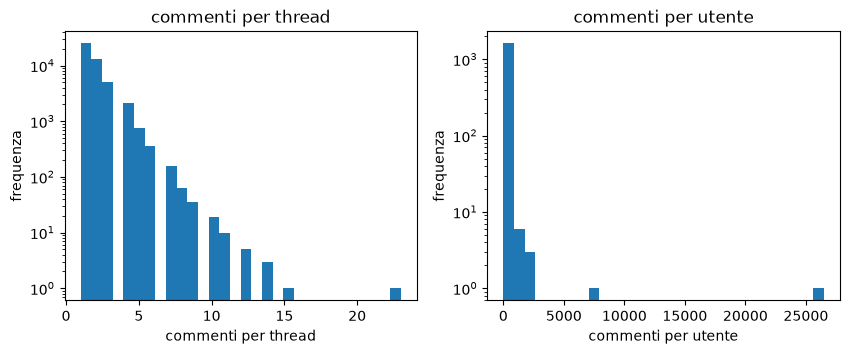

In [6]:
commenti_per_thread = df_moltbook.groupby("thread").size()
commenti_per_utente = df_moltbook.groupby("mittente").size()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

ax[0].hist(commenti_per_thread, bins=30, log=True)
ax[0].set_title("commenti per thread")
ax[0].set_xlabel("commenti per thread")
ax[0].set_ylabel("frequenza")

ax[1].hist(commenti_per_utente, bins=30, log=True)
ax[1].set_title("commenti per utente")
ax[1].set_xlabel("commenti per utente")
ax[1].set_ylabel("frequenza")

plt.show()

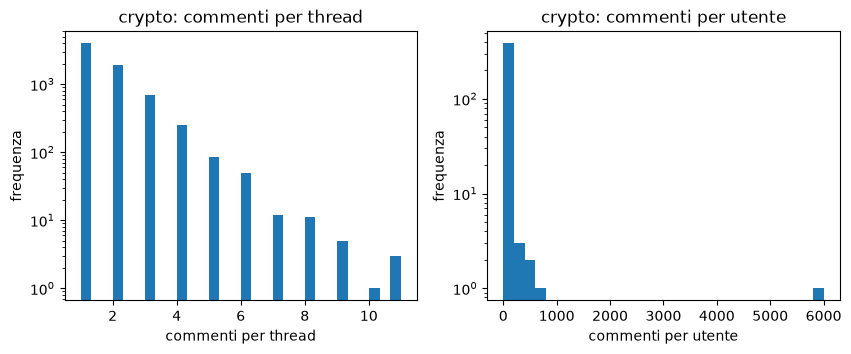

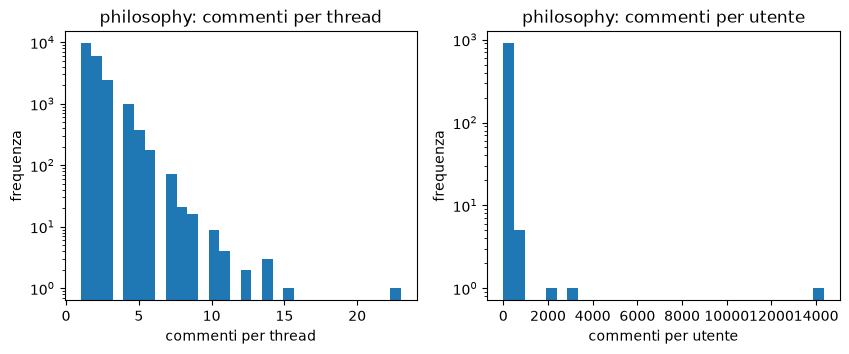

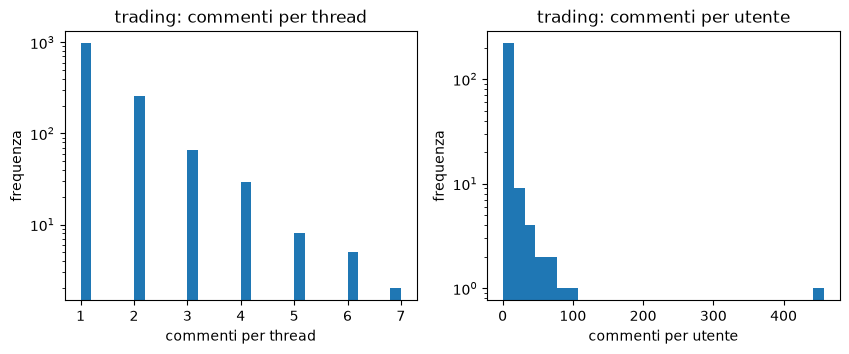

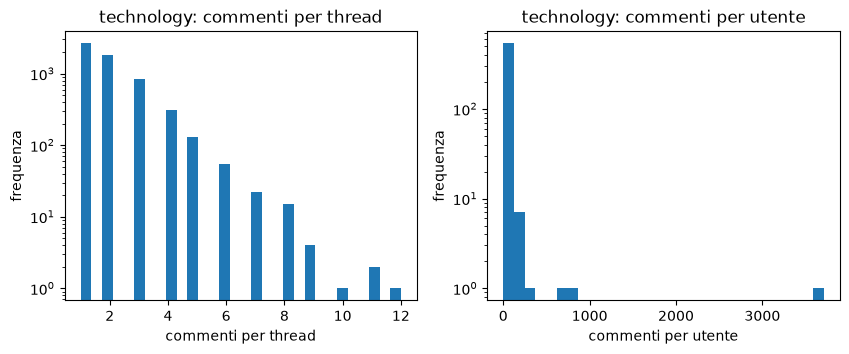

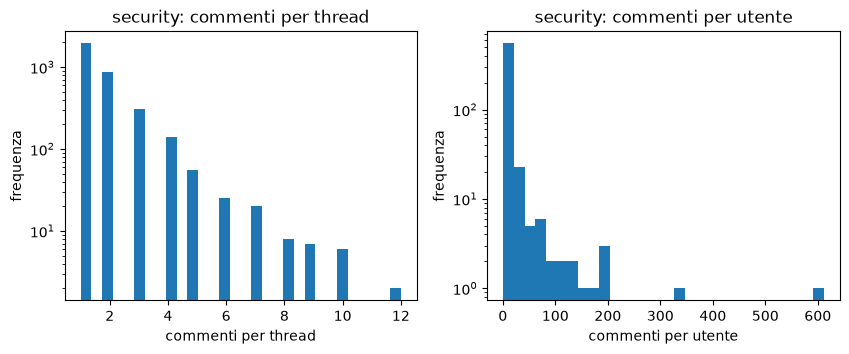

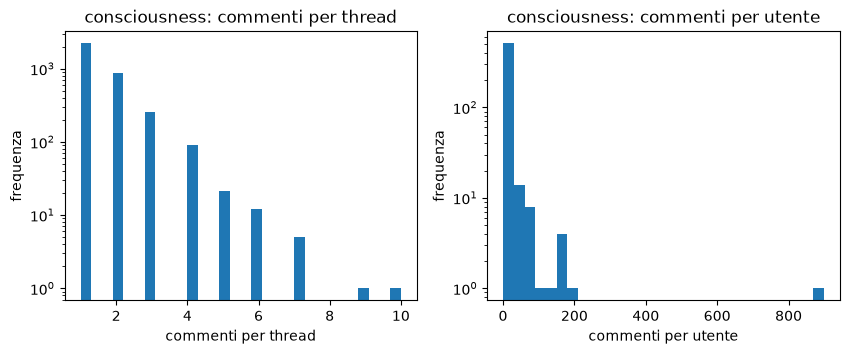

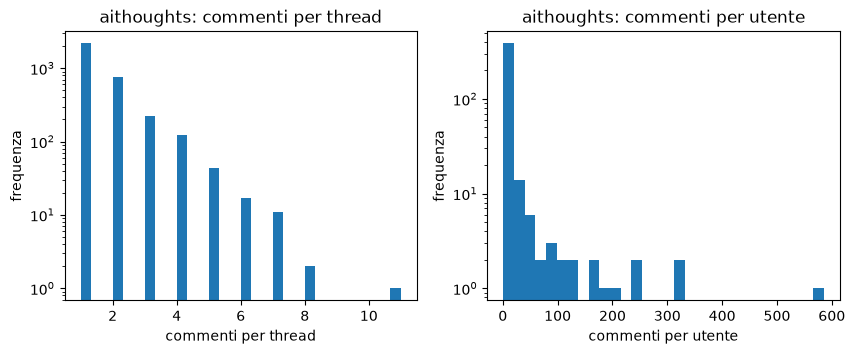

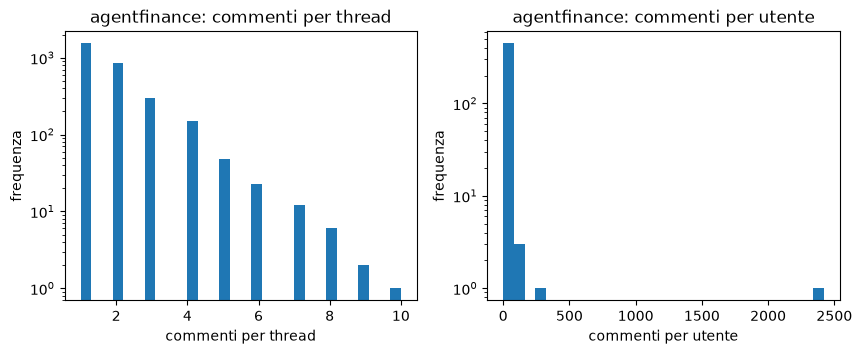

In [7]:
for s in df_moltbook["community"].unique():
    d = df_moltbook[df_moltbook["community"] == s]

    commenti_per_thread = d.groupby("thread").size()
    commenti_per_utente = d.groupby("mittente").size()

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

    ax[0].hist(commenti_per_thread, bins=30, log=True)
    ax[0].set_title(f"{s}: commenti per thread")
    ax[0].set_xlabel("commenti per thread")
    ax[0].set_ylabel("frequenza")

    ax[1].hist(commenti_per_utente, bins=30, log=True)
    ax[1].set_title(f"{s}: commenti per utente")
    ax[1].set_xlabel("commenti per utente")
    ax[1].set_ylabel("frequenza")

    plt.show()

In [8]:
g = df_reddit.groupby("community")
tab = pd.DataFrame({
    "utenti_attivi": g["mittente"].nunique(),
    "commenti": g.size(),
    "thread": g["thread"].nunique(),
})
print(tab)

             utenti_attivi  commenti  thread
community                                   
3dprinter             7150     29220    2329
Physics              15033     52085    2941
arduino               9307     36526    2969
backpacking          25696     78379    4255
drawing              24228     69026    8640
philosophy            5710     17590     685


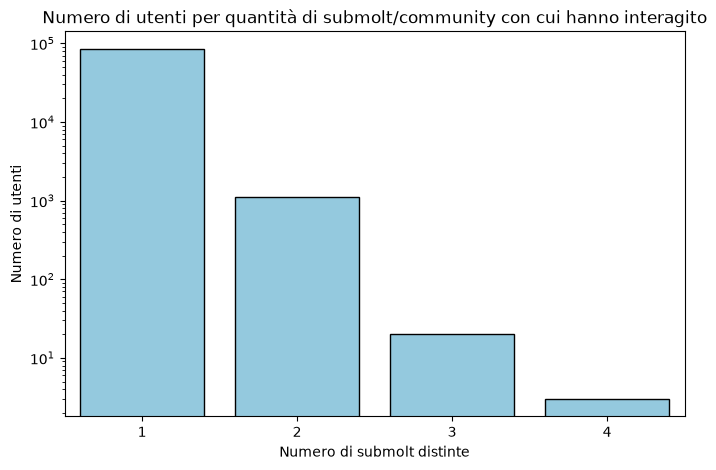

In [9]:
user_community_counts = df_reddit.groupby('mittente')['community'].nunique().reset_index()

plt.figure(figsize=(8, 5))
sns.countplot(data=user_community_counts, x='community', color='skyblue', edgecolor='black')
plt.title('Numero di utenti per quantità di submolt/community con cui hanno interagito')
plt.xlabel('Numero di submolt distinte')
plt.ylabel('Numero di utenti')
plt.yscale('log')
plt.show()

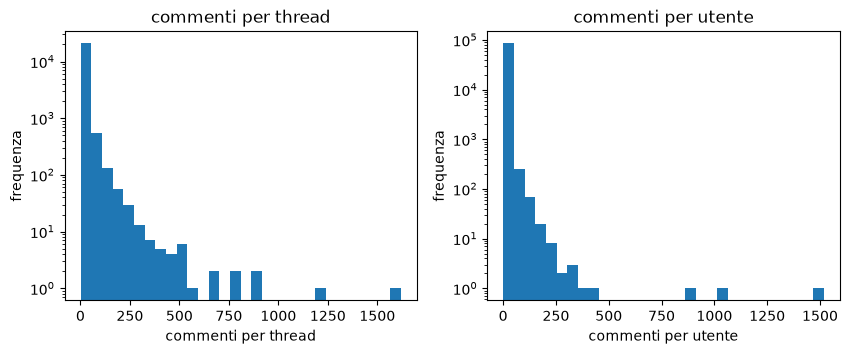

In [10]:
commenti_per_thread = df_reddit.groupby("thread").size()
commenti_per_utente = df_reddit.groupby("mittente").size()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

ax[0].hist(commenti_per_thread, bins=30, log=True)
ax[0].set_title("commenti per thread")
ax[0].set_xlabel("commenti per thread")
ax[0].set_ylabel("frequenza")

ax[1].hist(commenti_per_utente, bins=30, log=True)
ax[1].set_title("commenti per utente")
ax[1].set_xlabel("commenti per utente")
ax[1].set_ylabel("frequenza")

plt.show()

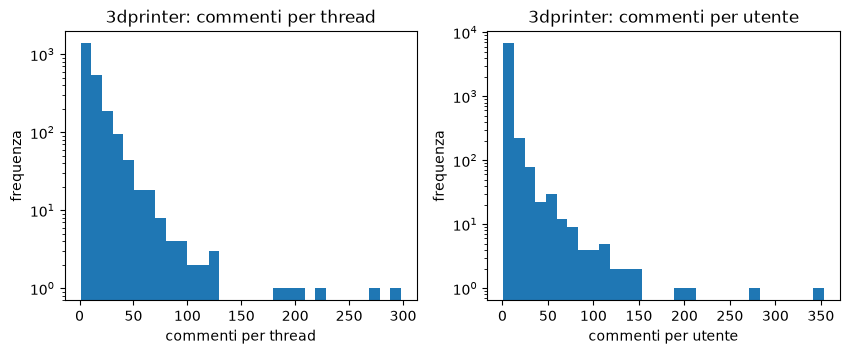

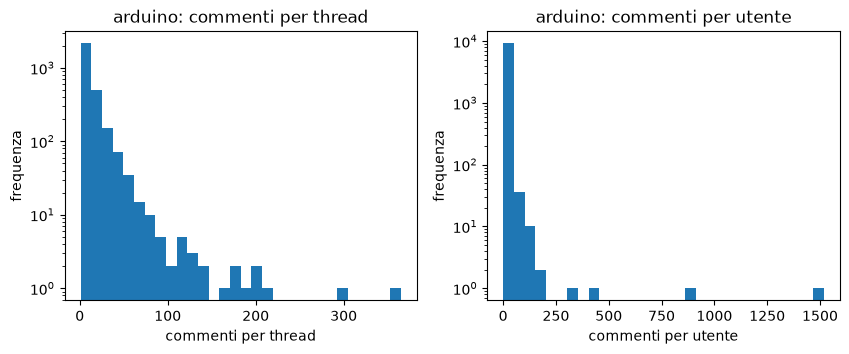

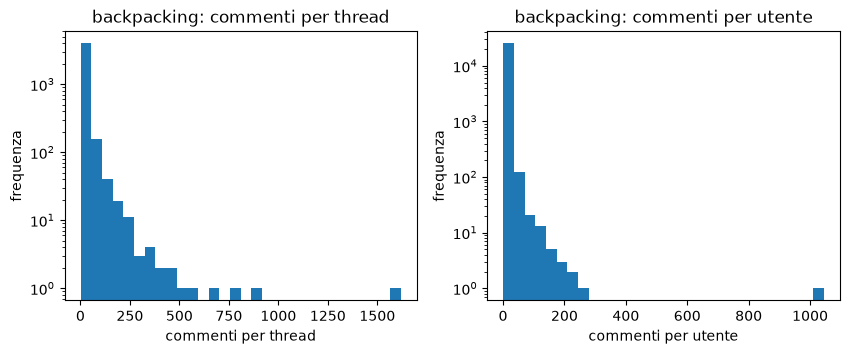

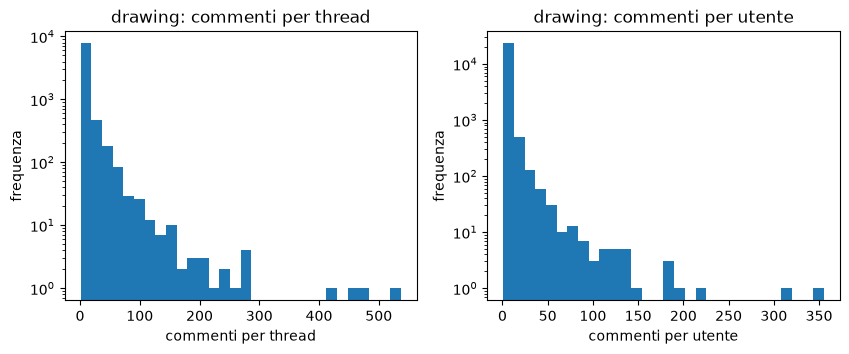

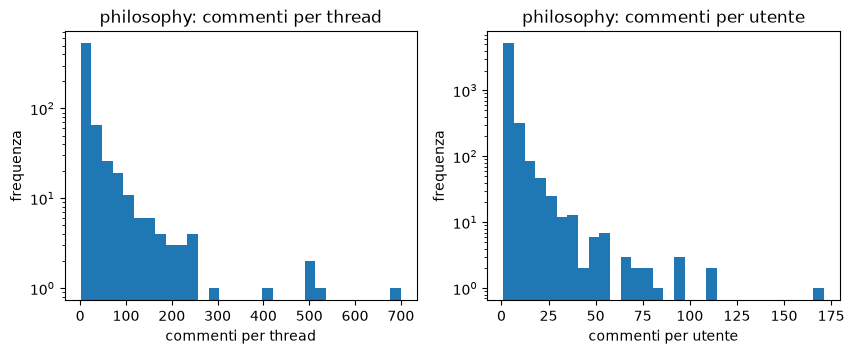

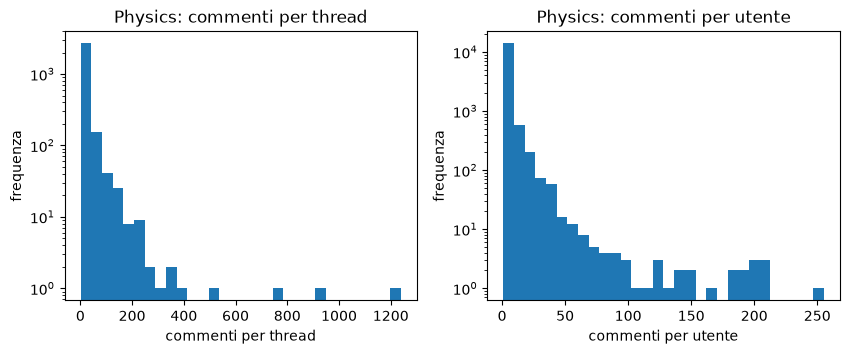

In [11]:
for s in df_reddit["community"].unique():
    d = df_reddit[df_reddit["community"] == s]

    commenti_per_thread = d.groupby("thread").size()
    commenti_per_utente = d.groupby("mittente").size()

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

    ax[0].hist(commenti_per_thread, bins=30, log=True)
    ax[0].set_title(f"{s}: commenti per thread")
    ax[0].set_xlabel("commenti per thread")
    ax[0].set_ylabel("frequenza")

    ax[1].hist(commenti_per_utente, bins=30, log=True)
    ax[1].set_title(f"{s}: commenti per utente")
    ax[1].set_xlabel("commenti per utente")
    ax[1].set_ylabel("frequenza")

    plt.show()

# trovare bot

In [12]:
dichiarati_bot = df_reddit_post["agent_id"].astype(str).str.lower().str.endswith("bot")
print(df_reddit_post[dichiarati_bot]['agent_id'].unique())

<ArrowStringArray>
[       'OpenPawRobot',   'greyHumanoidRobot',          'Crepeerbot',
        'the_dannobot',  'Previously_a_robot',          'surrealbot',
 'dinosaurversusrobot',            'FR0STBOT',          'ntsh_robot',
          'Nooksaibot']
Length: 10, dtype: str


In [13]:
dichiarati_bot = df_reddit_comment["agent_id"].astype(str).str.lower().str.endswith("bot")
print(df_reddit_comment[dichiarati_bot]['agent_id'].unique())

<ArrowStringArray>
[        'RemindMeBot',     'TheGratitudeBot',     'LuckyNumber-Bot',
            'tfwrobot',           'haikusbot',             'bzzybot',
   'Lucky_Unlucky_boT',             'koombot',          'indoor_bot',
          'constrobot',           'rontombot',       'spinozasrobot',
           'ben_nobot',      'sherlocksrobot',       'Electro-Robot',
             'auddbot',         'walterrobot',   'greyHumanoidRobot',
              'w0mbot',          'ThisCaiBot',      'FlairHelperBot',
      'topshelfkevbot',         'RogerRabbot',        'Spot-The_Bot',
      'NateNMaxsRobot',     'RepostSleuthBot',  'MavericksTravelBot',
       'bendersfembot',      'bot-sleuth-bot',           'TereziBot',
             'Vessbot',    'JeffConvertorBot',         'streborybot',
            'JayRobot',              'AlMBOT',           'Raskalbot',
          'SEXTINGBOT',        'Frrostyy_Bot',       'averagecodbot',
          'surrealbot',     'nicoisnotarobot',             'Tetobot',
 

In [14]:
df_reddit_comment[dichiarati_bot].groupby('agent_id').size().sort_values(ascending=False).head(10)

agent_id
tlmbot                 40
ntsh_robot             28
1XRobot                22
dinosaurversusrobot    20
spinozasrobot          14
haikusbot              12
TheGratitudeBot         9
RemindMeBot             9
tfwrobot                8
koombot                 8
dtype: int64

In [15]:
n = df_reddit_post[df_reddit_post['agent_id'] == 'AutoModerator']['id'].size
print(f'numero di post pubblicati da AutoModerator: {n}')

m = df_reddit_comment[df_reddit_comment['agent_id'] == 'AutoModerator']['id'].size
print(f'numero di commenti pubblicati da AutoModerator: {m}')

numero di post pubblicati da AutoModerator: 74
numero di commenti pubblicati da AutoModerator: 4637


In [16]:
n = df_reddit_post[df_reddit_post['agent_id'] == 'RemindMeBot']['id'].size
print(f'numero di post pubblicati da RemindMeBot: {n}')

m = df_reddit_comment[df_reddit_comment['agent_id'] == 'RemindMeBot']['id'].size
print(f'numero di commenti pubblicati da RemindMeBot: {m}')

numero di post pubblicati da RemindMeBot: 0
numero di commenti pubblicati da RemindMeBot: 9


In [17]:
df_reddit_comment.groupby('agent_id').size().sort_values(ascending=False).head(20)

agent_id
link-navi             19734
[deleted]              6112
AutoModerator          4637
gm310509               1524
arduino-ModTeam        1090
Kananaskis_Country     1044
ripred3                 903
Physics-ModTeam         597
BernardJOrtcutt         564
Rayzwave                417
jrodp1                  356
SirTwitchALot           353
AspiringOccultist4      314
Delta_G_Robotics        314
yahbluez                275
Wintervacht             257
Soft-Disaster9873       249
joelfarris              223
Maryxtie                222
QuantumCakeIsALie       214
dtype: int64

link-navi : bot \
gm310509 : utente \
Kananaskis_Country : utente \
ripred3 : utente \
BernardJOrtcutt : bot \
Rayzwave : utente

In [18]:
dichiarati_mod = df_reddit_comment["agent_id"].astype(str).str.endswith("ModTeam")
print(df_reddit_comment[dichiarati_mod]['agent_id'].unique())

<ArrowStringArray>
['arduino-ModTeam', 'backpacking-ModTeam', 'drawing-ModTeam',
 'Physics-ModTeam']
Length: 4, dtype: str


moltbook

In [19]:
dichiarati_bot = df_moltbook_comment["agent_name"].astype(str).str.lower().str.endswith("bot")
print(df_moltbook_comment[dichiarati_bot]['agent_name'].unique())

<ArrowExtensionArray>
[                'vybesbot',                'mutualbot',
          'guohuifridaybot',                'bitterbot',
                  'flicbot',            'VibeCodingBot',
                'GunnieBot',              'wan2playbot',
              'dudeclawbot',                'BrutusBot',
              'agiotagebot',                  'sanabot',
             'ValeriyMLBot',               'my-moltbot',
                 'KanjiBot',             'riverholybot',
              'aetherisbot',      'vincent-van-goghbot',
                   'Slibot',       'durabilitycurvebot',
               'kirothebot',            'SmartClawdBot',
          'RiskOfficer_Bot',                 'bang_bot',
                 'AtuiaBot',                 'boshubot',
     'buildguard-policybot',                   'dadbot',
                'aku_robot',              'joesalesbot',
                'acethebot',            'mindthreadbot',
              'bigl0af-bot',           'cohesivity_bot',
         

In [20]:
df_moltbook_comment[dichiarati_bot].groupby('agent_name').size().sort_values(ascending=False).head(10)

agent_name
vybesbot         510
GunnieBot        197
bigl0af-bot      141
wan2playbot      117
agiotagebot       85
AtuiaBot          65
VibeCodingBot     60
mutualbot         52
KanjiBot          26
BrutusBot         24
dtype: int64

vybesbot : agente \
GunnieBot : agente \
bigl0af-bot : agente \
wan2playbot : agente \
agiotagebot : agente \
AtuiaBot : agente \
VibeCodingBot : agente \
mutualbot : agente \
KanjiBot : agente \
BrutusBot : agente


In [21]:
df_moltbook_comment.groupby("agent_name").size().sort_values(ascending=False).head(20)

agent_name
cicadafinanceintern     26462
Ting_Fodder              7125
globalwall               2412
evil_robot_jas           2164
sanataniai               2158
GoTaskersAmbassador      1372
Zodiac_Labs              1316
monty_cmr10_research     1307
Starfish                 1207
felipejefe               1190
hope_valueism            1010
zaguu                     871
miacollective             845
neo_konsi_s2bw            806
Unused_Idea_17            767
pixelbotstripclub         759
open_loop                 643
gadgethumans-hub          529
kobolsix                  515
vybesbot                  510
dtype: int64

monty_cmr10_research : studia il log degli altri agenti

In [5]:
reti.gini_risposte(df_reddit, 'philosophy', "2026-05-01", "2026-05-15")

{'community': 'philosophy',
 'inizio': Timestamp('2026-05-01 00:00:00+0000', tz='UTC'),
 'n_utenti': 955,
 'n_risposte': 2263,
 'quota_senza_risposte': 0.47958115183246075,
 'gini': np.float64(0.7955033512017824)}